# Детекция ботов-парсеров по событиям внутри суточного окна

**Задача:** для каждой `cookie_id` выдать `score ∈ [0, 1]` — вероятность, что кука принадлежит сервису
автоматизированного сбора данных. Метрика — **Precision при Recall ≥ 0.7** (официальная реализация `metric.py`).

## Краткое описание решения

1. **Очистка событий** (`features.clean_events`): удаление полных дубликатов строк, **фильтр строго по окну**
   `window_start_ts <= event_ts < window_end_ts` (12% событий лежат после окна, среди них все `captcha_shown` — прямая
   утечка таргета), сортировка по времени (файл не отсортирован), нормализация `platform` (регистр — шум логирования).
2. **Признаки** (`features.py`, 110 шт., только по событиям внутри окна своей куки, без кросс-куки агрегатов):
   ритм событий и сессии, курсор мыши, содержание просмотров (разнообразие, глубина и «прыжки» по выдаче, повторы
   запросов, города, контакты), счётчики типов событий, разобранный User-Agent, возраст куки.
3. **Валидация:** test строго позже train → **expanding-window по времени**, 5 фолдов (11–19 апреля),
   официальная метрика `metric.precision_at_recall`, модели усредняются по 3 сидам.
4. **Модель:** LightGBM (неглубокие деревья, 500 итераций), обучение на всём train, усреднение по 5 сидам.

| модель | P@R≥0.7 (среднее по 5 фолдам) | pooled OOF | ROC-AUC |
|---|---|---|---|
| константа (доля ботов) | 0.079 | 0.081 | 0.500 |
| quickstart: RF на 2 признаках | 0.096 | 0.093 | 0.604 |
| правило «6 флагов из EDA» | 0.213 | 0.206 | 0.806 |
| LogReg на наших признаках | 0.681 | 0.687 | 0.930 |
| RandomForest на наших признаках | 0.637 | 0.667 | 0.917 |
| **LightGBM на наших признаках (финал)** | **0.788** | **0.770** | **0.938** |

Самые полезные группы признаков (абляция): ритм событий (без него 0.59), курсор (без него 0.58), содержание
просмотров (без него 0.70). Adversarial validation train vs test: ROC-AUC 0.505, т.е. сдвига нет, и валидационной
оценке ~0.77–0.79 можно доверять (с учётом шума ±0.03 из-за ~120 ботов на фолд).

**Запуск:** `pip install -r requirements.txt`, затем выполнить этот ноутбук целиком (Python 3.11, ~2 мин на CPU;
все сиды зафиксированы, `deterministic=True` в LightGBM). Результат — `submission.csv`.

**Использованные open-source библиотеки:** pandas, numpy, scikit-learn, LightGBM, matplotlib. Предобученные модели и
внешние API не используются.

## 0. Окружение и воспроизводимость

In [1]:
import sys, platform, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
import sklearn
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from metric import precision_at_recall            # официальная метрика
from features import load_data, clean_events, build_features, parse_user_agent

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__)

python 3.11.15 | pandas 2.2.3 | numpy 1.26.4 | sklearn 1.5.2 | lightgbm 4.5.0


## 1. Данные и что с ними не так

Прежде чем строить признаки, проверяем сам файл событий. Находки (подробности — в выводе ячеек ниже):

1. **События вне окна.** ~12% строк `events` лежат *после* `window_end_ts`. Их использовать нельзя — это будущее
   относительно момента скоринга.
2. **`captcha_shown` — утечка таргета.** Все показы капчи находятся только после окна, и 88% из них у ботов:
   капча — реакция антибота, т.е. следствие разметки. Фильтр по окну её автоматически убирает.
3. **Полные дубликаты строк** (~1.5%), одинаково часто у обоих классов → технический шум логирования, удаляем.
4. **Файл не отсортирован по времени** внутри куки → сортируем, иначе все интервалы между событиями будут мусором.
5. **`platform` записан в разном регистре/синонимами** (`web/WEB/Web/desktop`, `ios/IOS/iOS/iphone`). Внутри одной
   куки регистр меняется от события к событию — это логирование, а не поведение. Нормализуем к `web/android/ios`
   и **не** используем исходное написание как признак.

In [2]:
train, test, events = load_data("data")
meta = pd.concat([train, test], ignore_index=True)

print("train:", train.shape, "test:", test.shape, "events:", events.shape)
print("доля ботов в train:", round(train.target.mean(), 4))
print("пересечение кук train/test:", len(set(train.cookie_id) & set(test.cookie_id)))
print("окна train:", train.window_start_ts.min().date(), "…", train.window_start_ts.max().date(),
      "| окна test:", test.window_start_ts.min().date(), "…", test.window_start_ts.max().date())
print("длина окна всегда 1 день:", ((meta.window_end_ts - meta.window_start_ts) == pd.Timedelta("1D")).all())
events.head()

train: (11091, 5) test: (4909, 4) events: (328905, 14)
доля ботов в train: 0.0811
пересечение кук train/test: 0
окна train: 2026-04-06 … 2026-04-19 | окна test: 2026-04-20 … 2026-04-26
длина окна всегда 1 день: True


,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y
0,ck_5efbea1befdefe1b,2026-04-26 09:11:24,200,item_view,desktop,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,1027450.0,elektronika,kaliningrad,pro,NaN,NaN,NaN,NaN
1,ck_c4ca1434f3778f1d,2026-04-20 14:04:31,100,search_results_view,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,NaN,telefony,habarovsk,NaN,iphone 13 128,4.0,NaN,NaN
2,ck_d274382b19488771,2026-04-13 12:02:56,200,item_view,WEB,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0
3,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,100,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN
4,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,100,search_results_view,WEB,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN


In [3]:
e = events.merge(meta[["cookie_id", "window_start_ts", "window_end_ts", "target"]], on="cookie_id", how="left")
e["position"] = np.select(
    [e.event_ts < e.window_start_ts, e.event_ts >= e.window_end_ts], ["before", "after"], "inside")

print("положение событий относительно окна:\n", e.position.value_counts(normalize=True).round(3), "\n")
print("captcha_shown по положению и таргету (train):")
print(pd.crosstab(e[e.event_name == "captcha_shown"].position,
                  e[e.event_name == "captcha_shown"].target.map({0: "human", 1: "bot"}).fillna("test")), "\n")

dup = events.duplicated()
print(f"полных дубликатов строк: {dup.sum()} ({dup.mean():.2%})")
print("доля дублей у людей / ботов:",
      e[dup.values & (e.target == 0)].shape[0] / (e.target == 0).sum(),
      e[dup.values & (e.target == 1)].shape[0] / (e.target == 1).sum())
sorted_share = events.groupby("cookie_id").event_ts.apply(lambda s: s.is_monotonic_increasing).mean()
print(f"кук, у которых события в файле уже отсортированы по времени: {sorted_share:.1%}\n")

print("написания platform:", events.platform.value_counts().to_dict())
print("пропуски по колонкам:\n", events.isna().mean().round(3).to_string())

положение событий относительно окна:
 position
inside    0.876
after     0.124
Name: proportion, dtype: float64 

captcha_shown по положению и таргету (train):
target     bot  human
position             
after     6970    958 

полных дубликатов строк: 4863 (1.48%)
доля дублей у людей / ботов: 0.014839361068682527 0.01423611111111111


кук, у которых события в файле уже отсортированы по времени: 3.5%

написания platform: {'desktop': 46866, 'WEB': 46476, 'Web': 46365, 'web': 45951, 'ANDROID': 42462, 'Android': 42254, 'android': 42159, 'iphone': 4103, 'IOS': 4100, 'iOS': 4091, 'ios': 4078}
пропуски по колонкам:
 cookie_id        0.000
event_ts         0.000
eid              0.000
event_name       0.000
platform         0.000
user_agent       0.000
item_id          0.348
item_category    0.100
item_location    0.072
seller_type      0.407
search_query     0.695
search_page      0.695
pointer_x        0.670
pointer_y        0.670


Очистка реализована в `features.clean_events`: дедупликация → фильтр `window_start_ts <= event_ts < window_end_ts`
→ сортировка → нормализация платформы → интервал `dt` до предыдущего события куки.

In [4]:
ev = clean_events(events, meta)
print("событий после очистки:", len(ev), "| captcha_shown осталось:", (ev.event_name == "captcha_shown").sum())
print("кук без единого события в окне: train", (~train.cookie_id.isin(ev.cookie_id)).sum(),
      "test", (~test.cookie_id.isin(ev.cookie_id)).sum())
print(ev.platform_norm.value_counts())

событий после очистки: 283833 | captcha_shown осталось: 0
кук без единого события в окне: train 0 test 0
platform_norm
web        158898
android    110556
ios         14379
Name: count, dtype: int64


## 2. Разведочный анализ: чем бот отличается от человека

Смотрим только на события внутри окна и только на train.

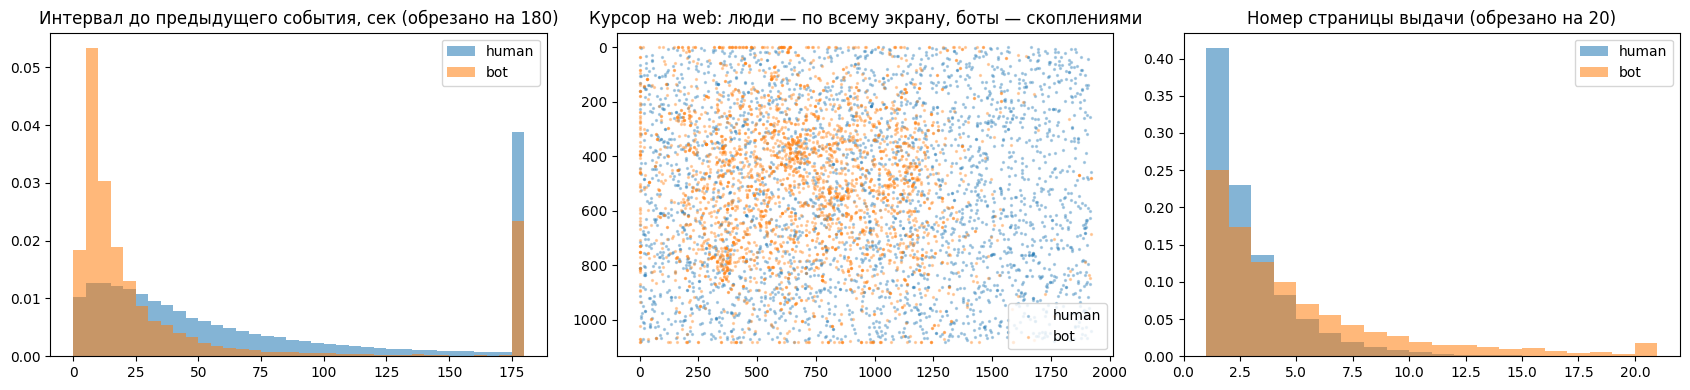

In [5]:
evt = ev.merge(train[["cookie_id", "target"]], on="cookie_id")
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

# (a) интервалы между соседними событиями
bins = np.arange(0, 181, 5)
for t, name in [(0, "human"), (1, "bot")]:
    ax[0].hist(evt.loc[evt.target == t, "dt"].clip(upper=180), bins=bins, density=True, alpha=0.55, label=name)
ax[0].set_title("Интервал до предыдущего события, сек (обрезано на 180)"); ax[0].legend()

# (b) координаты курсора (только web)
w = evt[(evt.platform_norm == "web") & evt.pointer_x.notna()]
for t, name in [(0, "human"), (1, "bot")]:
    s = w[w.target == t].sample(3000, random_state=RANDOM_STATE, replace=True)
    ax[1].scatter(s.pointer_x, s.pointer_y, s=2, alpha=0.3, label=name)
ax[1].invert_yaxis(); ax[1].set_title("Курсор на web: люди — по всему экрану, боты — скоплениями"); ax[1].legend()

# (c) глубина выдачи
se = evt[evt.event_name == "search_results_view"]
for t, name in [(0, "human"), (1, "bot")]:
    ax[2].hist(se.loc[se.target == t, "search_page"].clip(upper=20), bins=np.arange(1, 22), density=True,
               alpha=0.55, label=name)
ax[2].set_title("Номер страницы выдачи (обрезано на 20)"); ax[2].legend()
plt.tight_layout(); plt.show()

In [6]:
web = evt[evt.platform_norm == "web"]
print("доля web-событий с координатами курсора:", web.groupby("target").pointer_x.apply(lambda s: s.notna().mean()).round(3).to_dict())
print("событий с pointer_x=1920 или pointer_y=1080 (за границей экрана 1920×1080):",
      web.groupby("target").apply(lambda d: ((d.pointer_x >= 1920) | (d.pointer_y >= 1080)).sum()).to_dict())
ua = parse_user_agent(evt.drop_duplicates("cookie_id").set_index("cookie_id").user_agent)
ua = ua.join(train.set_index("cookie_id").target)
print("доля кук с headless-UA:", ua.groupby("target").ua_headless.mean().round(3).to_dict())
print("распределение событий по типам:")
print(pd.crosstab(evt.event_name, evt.target, normalize="columns").round(3))

доля web-событий с координатами курсора: {0: 0.662, 1: 0.33}
событий с pointer_x=1920 или pointer_y=1080 (за границей экрана 1920×1080): {0: 18, 1: 150}
доля кук с headless-UA: {0: 0.028, 1: 0.105}
распределение событий по типам:
target                    0      1
event_name                        
contact_chat_open     0.020  0.014
contact_message_sent  0.010  0.008
contact_phone_show    0.037  0.026
favorite_add          0.066  0.027
item_view             0.365  0.437
login                 0.022  0.008
photo_swipe           0.123  0.070
search_results_view   0.305  0.352
seller_page_view      0.053  0.059


**Выводы EDA**, которые легли в признаки:

* **Ритм.** У ботов интервалы между событиями короче и сконцентрированы в диапазоне ~4–20 с, у людей — длинный
  «лог-нормальный» хвост. Внутри сессий у ботов больше событий в минуту.
* **Курсор.** У людей координаты равномерно покрывают экран, у скриптов — скопления в левой и центральной части экрана (x < ~1300) и на верхней кромке, маленькие шаги
  между событиями, «невозможные» значения `x=1920 / y=1080`, и в 2 раза чаще координаты не передаются вовсе.
* **Контент.** Боты глубже листают выдачу и прыгают по номерам страниц, многократно повторяют запросы, смотрят
  объявления из большего числа городов (сводки по регионам), чаще открывают телефоны (выгрузка контактов).
* **User-Agent.** `HeadlessChrome` — сильный, но редкий сигнал (≈10% ботов). Сырую строку UA использовать как
  категорию нельзя: модель запомнит конкретные версии браузеров из train. Поэтому UA разбирается на обобщаемые части.
* **Кука.** Боты чаще используют «свежие» куки (возраст < 3 дней).

## 3. Признаки

Все признаки считаются в `features.py` **только по событиям внутри окна своей куки**, т.е. доступны на момент
`window_end_ts`. Кросс-куки агрегатов (популярность объявления, target encoding) нет — они либо заглядывают в будущее,
либо протекают между train и test. Группы:

| группа | примеры | идея |
|---|---|---|
| `meta` | возраст куки на конец окна | боты чаще на свежих куках |
| `counts` | число событий каждого типа, доли, фото/контакты/избранное на просмотр, энтропия типов | структура активности |
| `timing` | квантили/CV интервалов, доля интервалов 3–20 с, сессии (разрыв > 30 мин), событий в минуту, ночная активность | скрипт работает быстрее и ровнее человека |
| `content` | число уникальных объявлений/категорий/городов/запросов, энтропии, глубина и «прыжки» по страницам выдачи, повторы запросов, действия над неоткрытыми объявлениями, телефоны по разным объявлениям | что и как «смотрит» кука |
| `pointer` | доля событий с курсором, разброс и шаг курсора, расстояние до центра, края экрана и выход за них | биометрия мыши |
| `user_agent` | headless, Linux-десктоп, семейство и мажорная версия браузера, несоответствие UA и платформы, число UA у куки | технический отпечаток, обобщённый |

Пропуски (нет интервалов при одном событии, нет web-событий для признаков курсора, нет поисков) оставлены `NaN` —
LightGBM обрабатывает их нативно, и сам факт отсутствия информативен.

In [7]:
X, groups = build_features(meta, ev)
X_train = X.loc[train.cookie_id].reset_index(drop=True)
X_test = X.loc[test.cookie_id].reset_index(drop=True)
y = train.target.to_numpy()
FEATURES = list(X.columns)

print("матрица признаков:", X.shape)
print({g: len(c) for g, c in groups.items()})
assert X.index.is_unique and len(X_train) == len(train) and len(X_test) == len(test)
X_train.describe().T.head(15)

матрица признаков: (16000, 110)
{'meta': 1, 'counts': 25, 'timing': 33, 'content': 26, 'pointer': 11, 'user_agent': 14}


,count,mean,std,min,25%,50%,75%,max
cookie_age_days,11091.0,72.867225,66.993073,1.012361,14.114740,60.759178,109.552766,450.284873
n_events,11091.0,17.625462,17.437804,1.000000,6.000000,12.000000,23.000000,165.000000
cnt_search_results_view,11091.0,5.482463,5.969530,0.000000,2.000000,4.000000,7.000000,64.000000
share_search_results_view,11091.0,0.310192,0.173813,0.000000,0.211111,0.303571,0.400000,1.000000
cnt_item_view,11091.0,6.598684,7.142721,0.000000,2.000000,4.000000,9.000000,88.000000
share_item_view,11091.0,0.369047,0.182897,0.000000,0.272727,0.363636,0.466667,1.000000
cnt_photo_swipe,11091.0,2.038410,2.354621,0.000000,0.000000,1.000000,3.000000,23.000000
share_photo_swipe,11091.0,0.123119,0.127056,0.000000,0.000000,0.102941,0.178571,1.000000
cnt_seller_page_view,11091.0,0.951222,1.323663,0.000000,0.000000,1.000000,1.000000,14.000000
share_seller_page_view,11091.0,0.053623,0.082510,0.000000,0.000000,0.022222,0.083333,1.000000


## 4. Схема валидации

Тест (окна 20–26 апреля) лежит **строго позже** train (6–19 апреля), поэтому валидация — по времени,
**expanding window**: обучаемся на всех днях до даты `a`, валидируемся на днях `[a, b)`. Пять фолдов по ~2 дня
(последний — 1 день) покрывают вторую половину train.

* Метрика считается официальной функцией `metric.precision_at_recall` отдельно на каждом фолде
  (в каждом ~100–150 ботов, так что одно число шумное, ±0.03). Смотрим **среднее по фолдам** и **pooled** — метрику
  по объединённым OOF-предсказаниям всех фолдов, плюс ROC-AUC и PR-AUC для диагностики.
* Бустинг усредняется по 3 сидам внутри каждого фолда, чтобы сравнение моделей меньше зависело от случайности.
* Дополнительно в п.8 проверяем adversarial validation, что между train и test нет сдвига распределений.

In [8]:
VALID_FOLDS = [("2026-04-11", "2026-04-13"), ("2026-04-13", "2026-04-15"), ("2026-04-15", "2026-04-17"),
               ("2026-04-17", "2026-04-19"), ("2026-04-19", "2026-04-20")]
window_day = train.window_start_ts

for a, b in VALID_FOLDS:
    tr_mask, va_mask = window_day < a, (window_day >= a) & (window_day < b)
    print(f"train < {a}: {tr_mask.sum():5d} кук, {y[tr_mask].sum():3d} ботов | "
          f"valid [{a}, {b}): {va_mask.sum():4d} кук, {y[va_mask].sum():3d} ботов")


def time_cv(make_model, cols, seeds=(0,), name=None):
    '''Expanding-window CV. make_model(seed) -> sklearn-совместимый классификатор.
    Возвращает строку результатов и OOF-предсказания (NaN для кук, которые ни разу не были в валидации).'''
    fold_scores, oof = [], np.full(len(y), np.nan)
    for a, b in VALID_FOLDS:
        tr_mask = (window_day < a).to_numpy()
        va_mask = ((window_day >= a) & (window_day < b)).to_numpy()
        preds = [make_model(s).fit(X_train.loc[tr_mask, cols], y[tr_mask])
                 .predict_proba(X_train.loc[va_mask, cols])[:, 1] for s in seeds]
        oof[va_mask] = np.mean(preds, axis=0)
        fold_scores.append(precision_at_recall(y[va_mask], oof[va_mask]))
    m = ~np.isnan(oof)
    row = {"model": name, "P@R0.7 mean": np.mean(fold_scores), "P@R0.7 std": np.std(fold_scores),
           "P@R0.7 pooled": precision_at_recall(y[m], oof[m]),
           "ROC-AUC": roc_auc_score(y[m], oof[m]), "PR-AUC": average_precision_score(y[m], oof[m]),
           "folds": np.round(fold_scores, 3)}
    return row, oof

train < 2026-04-11:  4217 кук, 345 ботов | valid [2026-04-11, 2026-04-13): 1713 кук, 146 ботов
train < 2026-04-13:  5930 кук, 491 ботов | valid [2026-04-13, 2026-04-15): 1669 кук, 123 ботов
train < 2026-04-15:  7599 кук, 614 ботов | valid [2026-04-15, 2026-04-17): 1541 кук, 125 ботов
train < 2026-04-17:  9140 кук, 739 ботов | valid [2026-04-17, 2026-04-19): 1319 кук, 118 ботов
train < 2026-04-19: 10459 кук, 857 ботов | valid [2026-04-19, 2026-04-20):  632 кук,  42 ботов


## 5. Baseline и сравнение моделей

* **константа** — метрика равна доле ботов;
* **quickstart** — RandomForest на двух признаках (`n_events`, число уникальных объявлений) из стартового ноутбука;
* **правило «headless UA»** — самая очевидная эвристика антибота. Она ловит только ~10% ботов, поэтому порога с
  recall ≥ 0.7 у неё нет, кроме «отметить всех», и метрика совпадает с константой;
* **правило «6 флагов»** — сумма подозрительных флагов из EDA (быстрый ритм, глубокая выдача, нет курсора,
  свежая кука, headless, высокая частота событий), без обучения;
* **логистическая регрессия** и **RandomForest** на всех наших признаках;
* **LightGBM** на всех признаках — основная модель.

In [9]:
LGB_PARAMS = dict(
    objective="binary", learning_rate=0.03, n_estimators=500,
    num_leaves=15, min_child_samples=20,            # неглубокие деревья: ботов в train всего ~900
    feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
    deterministic=True, force_col_wise=True, n_jobs=4, verbose=-1,
)
make_lgbm = lambda seed: lgb.LGBMClassifier(**LGB_PARAMS, random_state=seed)


def heuristic_score(X):
    '''Ручное правило без обучения: число «подозрительных» флагов, пороги взяты из EDA.
    Малая добавка по числу событий разбивает равные суммы (больше событий — увереннее).'''
    flags = pd.DataFrame({
        "headless_ua":  X.ua_headless == 1,
        "fast_rhythm":  X.insess_dt_median.fillna(np.inf) < 25,      # медианный интервал в сессии < 25 с
        "deep_search":  X.search_page_mean.fillna(0) > 3,            # в среднем дальше 3-й страницы выдачи
        "no_pointer":   X.pointer_present_share.fillna(1) < 0.5,     # web без координат курсора
        "young_cookie": X.cookie_age_days < 3,
        "high_rate":    X.mean_session_rate > 2,                     # > 2 событий в минуту в сессии
    })
    return flags.sum(axis=1).to_numpy() + 0.01 * X.n_events.rank(pct=True).to_numpy()


class RuleModel:
    '''Обёртка, чтобы правило/константа прогонялись через ту же time_cv, что и модели.'''
    def __init__(self, score_fn): self.score_fn = score_fn
    def fit(self, X, y): return self
    def predict_proba(self, X):
        s = np.asarray(self.score_fn(X), dtype=float)
        return np.c_[-s, s]          # для метрики важен только порядок, нормировка не нужна


results, oofs = [], {}
experiments = [
    ("константа",               lambda s: RuleModel(lambda X: np.zeros(len(X))), FEATURES, (0,)),
    ("quickstart RF (2 признака)", lambda s: RandomForestClassifier(300, min_samples_leaf=3, random_state=s, n_jobs=-1),
                                  ["n_events", "nuniq_item_id"], (0,)),
    ("правило: headless UA",    lambda s: RuleModel(lambda X: X.ua_headless), FEATURES, (0,)),
    ("правило: 6 флагов из EDA", lambda s: RuleModel(heuristic_score), FEATURES, (0,)),
    ("LogReg, все признаки",    lambda s: make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                                        StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)),
                                  FEATURES, (0,)),
    ("RandomForest, все признаки", lambda s: make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                                           RandomForestClassifier(500, min_samples_leaf=3, max_features=0.3,
                                                                                  random_state=s, n_jobs=-1)),
                                  FEATURES, (0,)),
    ("LightGBM, все признаки",  make_lgbm, FEATURES, (0, 1, 2)),
]
for name, make, cols, seeds in experiments:
    row, oofs[name] = time_cv(make, cols, seeds, name)
    results.append(row)

models_table = pd.DataFrame(results).set_index("model")
models_table.round(4)

,P@R0.7 mean,P@R0.7 std,P@R0.7 pooled,ROC-AUC,PR-AUC,folds
model,,,,,,
константа,0.0792,0.0082,0.0806,0.5000,0.0806,"[0.085, 0.074, 0.081, 0.089, 0.066]"
quickstart RF (2 признака),0.0957,0.0081,0.0932,0.6035,0.2036,"[0.102, 0.087, 0.102, 0.103, 0.085]"
правило: headless UA,0.0792,0.0082,0.0806,0.5402,0.0987,"[0.085, 0.074, 0.081, 0.089, 0.066]"
правило: 6 флагов из EDA,0.2128,0.0226,0.2064,0.8055,0.4219,"[0.214, 0.2, 0.184, 0.214, 0.252]"
"LogReg, все признаки",0.6811,0.0486,0.6867,0.9300,0.7459,"[0.602, 0.719, 0.704, 0.648, 0.732]"
"RandomForest, все признаки",0.6369,0.0861,0.6667,0.9170,0.7364,"[0.632, 0.494, 0.607, 0.728, 0.723]"
"LightGBM, все признаки",0.7877,0.0467,0.7698,0.9382,0.7917,"[0.798, 0.698, 0.795, 0.814, 0.833]"


Бустинг заметно лучше линейной модели и случайного леса: зависимости сильно нелинейные (например, «короткие интервалы»
важны только в сочетании с большим числом событий), а `NaN` в признаках курсора/поиска несут смысл.
Подбор гиперпараметров LightGBM (глубина, `feature_fraction`, `lambda_l2`, `is_unbalance`, число деревьев) давал
разброс в пределах шума метрики (±0.02), поэтому оставлены умеренные «разумные» значения без агрессивного тюнинга.

## 6. Абляция по группам признаков

Для каждой группы: качество модели **только** на ней и качество **без** неё. Это отвечает на вопрос, какие идеи
действительно работают.

In [10]:
abl = []
for g, cols in groups.items():
    only, _ = time_cv(make_lgbm, cols, (0, 1, 2), f"только {g}")
    without, _ = time_cv(make_lgbm, [c for c in FEATURES if c not in set(cols)], (0, 1, 2), f"без {g}")
    abl.append({"группа": g, "n признаков": len(cols),
                "только группа: P@R0.7 mean": only["P@R0.7 mean"], "только группа: ROC-AUC": only["ROC-AUC"],
                "без группы: P@R0.7 mean": without["P@R0.7 mean"], "без группы: P@R0.7 pooled": without["P@R0.7 pooled"]})
full = models_table.loc["LightGBM, все признаки"]
print(f"все признаки: P@R0.7 mean = {full['P@R0.7 mean']:.4f}, pooled = {full['P@R0.7 pooled']:.4f}")
pd.DataFrame(abl).set_index("группа").round(4)

все признаки: P@R0.7 mean = 0.7877, pooled = 0.7698


,n признаков,только группа: P@R0.7 mean,только группа: ROC-AUC,без группы: P@R0.7 mean,без группы: P@R0.7 pooled
группа,,,,,
meta,1,0.1029,0.6163,0.7820,0.7791
counts,25,0.1761,0.7613,0.7399,0.7307
timing,33,0.3106,0.8504,0.5917,0.6082
content,26,0.2817,0.8367,0.6974,0.6795
pointer,11,0.1158,0.8085,0.5847,0.5800
user_agent,14,0.1115,0.6291,0.7790,0.7593


Главный вклад дают **ритм событий** (`timing`), **курсор** (`pointer`) и **содержание просмотров** (`content`):
убирание любой из этих групп роняет метрику на 0.09–0.20. Группы `meta` и `user_agent` сами по себе слабые и почти
не влияют на итог (их сигнал частично дублируется поведенческими признаками), но оставлены: headless-UA и свежесть
куки — интерпретируемые и дешёвые сигналы, которые помогают на части ботов.

## 7. Важность признаков и анализ ошибок

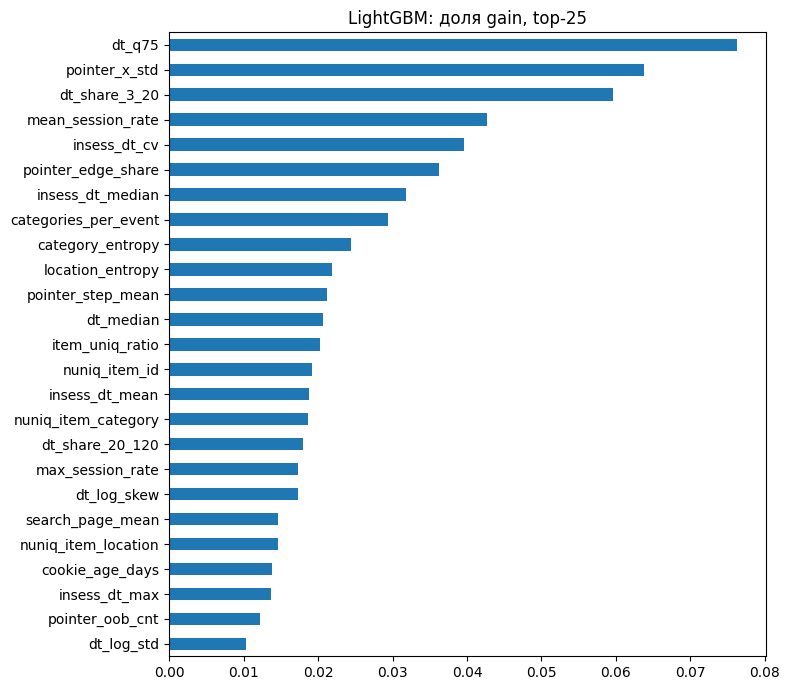

In [11]:
model = make_lgbm(RANDOM_STATE).fit(X_train[FEATURES], y)
imp = pd.Series(model.booster_.feature_importance("gain"), FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False)
imp.head(25)[::-1].plot.barh(figsize=(8, 7), title="LightGBM: доля gain, top-25")
plt.tight_layout(); plt.show()

In [12]:
oof = oofs["LightGBM, все признаки"]
m = ~np.isnan(oof)
d = X_train[m].assign(y=y[m], score=oof[m])
thr = np.quantile(d.score[d.y == 1], 0.30)            # порог, при котором recall ≈ 0.7
d["platform"] = np.select([d.platform_web == 1, d.platform_android == 1], ["web", "android"], "ios")
d["n_events_bin"] = pd.cut(d.n_events, [0, 3, 6, 10, 20, 40, 1000])

print("recall ботов при пороге recall=0.7 в разрезе платформы и числа событий:")
print(d[d.y == 1].groupby("platform").score.apply(lambda s: (s >= thr).mean()).round(3).to_dict())
print(d[d.y == 1].groupby("n_events_bin").score.apply(lambda s: (s >= thr).mean()).round(3).to_dict())

recall ботов при пороге recall=0.7 в разрезе платформы и числа событий:
{'android': 0.541, 'ios': 0.214, 'web': 0.793}
{Interval(0, 3, closed='right'): 0.111, Interval(3, 6, closed='right'): 0.519, Interval(6, 10, closed='right'): 0.629, Interval(10, 20, closed='right'): 0.651, Interval(20, 40, closed='right'): 0.75, Interval(40, 1000, closed='right'): 0.91}


Модель хуже всего ловит **мобильных ботов** (нет курсора — теряется одна из сильнейших групп) и **кук с 1–5
событиями** (по паре событий ритм и разнообразие не оценить). Часть «ботов» в разметке по сырым событиям
неотличима от людей: метка выставлена по источнику трафика, а не по поведению, — это задаёт потолок метрики.

## 8. Adversarial validation: похож ли test на train

Обучаем классификатор отличать train-куки от test-кук на тех же признаках. AUC ≈ 0.5 означает, что распределения
совпадают и временная валидация на train корректно оценивает качество на test.

In [13]:
X_adv = pd.concat([X_train, X_test], ignore_index=True)
y_adv = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
p_adv = cross_val_predict(make_lgbm(RANDOM_STATE), X_adv, y_adv,
                          cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
print("adversarial ROC-AUC:", round(roc_auc_score(y_adv, p_adv), 4))

adversarial ROC-AUC: 0.5054


## 9. Финальная модель и сабмит

LightGBM с параметрами выше, обучен на **всём train** (все 14 дней), предсказания усреднены по 5 сидам —
это снижает дисперсию ранжирования, что важно для метрики на пороге. Число деревьев фиксировано (500), без
early stopping на тесте.

In [14]:
FINAL_SEEDS = [RANDOM_STATE + i for i in range(5)]
test_score = np.mean([make_lgbm(s).fit(X_train[FEATURES], y).predict_proba(X_test[FEATURES])[:, 1]
                      for s in FINAL_SEEDS], axis=0)

submission = pd.DataFrame({"cookie_id": test.cookie_id, "score": test_score})

# проверки формата
sample = pd.read_csv("sample_submission.csv")
assert list(submission.columns) == ["cookie_id", "score"]
assert submission.cookie_id.is_unique and len(submission) == len(test)
assert set(submission.cookie_id) == set(test.cookie_id) == set(sample.cookie_id)
assert submission.score.between(0, 1).all() and submission.score.notna().all()

submission.to_csv("submission.csv", index=False)
print(submission.shape, "| средний score:", round(submission.score.mean(), 4),
      "| уникальных score:", submission.score.nunique())
submission.head()

(4909, 2) | средний score: 0.0793 | уникальных score: 4909


,cookie_id,score
0,ck_315fb710a0e371e7,0.000899
1,ck_a76ee3b3e3e522fd,0.027318
2,ck_94c9a4d382689e82,0.056027
3,ck_8eaf9509ad9462a0,0.000334
4,ck_9a88a5a989cb5bc6,0.007257


## 10. Итоги, ограничения, что ещё можно сделать

**Что получилось.** Поведенческие признаки поднимают P@R≥0.7 с 0.10 (quickstart) и 0.21 (ручные правила) до
~0.78 на честной временной валидации. Модель опирается в основном на *поведение* (ритм, курсор, навигация), а не на
технические отпечатки: при удалении всех UA-признаков метрика почти не меняется (0.779 против 0.788), так что
модель не сломается от простой смены User-Agent.

**Что пробовал и не взял:**
* другие модели — LogReg, RandomForest, sklearn HistGradientBoosting (0.75) — стабильно хуже LightGBM;
* тюнинг LightGBM (`num_leaves` 7/15/31, `feature_fraction` 0.3–0.7, `lambda_l2` до 10, `is_unbalance`,
  300–900 деревьев) — все варианты в пределах шума ±0.02, поэтому оставлены умеренные значения, чтобы не
  переобучиться под 5 валидационных фолдов;
* дополнительные признаки последовательности (действия над неоткрытыми объявлениями, повторы интервалов) и время
  создания куки (час, день недели) — почти нулевой вклад; оставлены только те, у которых есть понятная логика;
* сырая строка User-Agent и исходное написание `platform` как категории **сознательно не используются**:
  первое запоминает конкретные версии браузеров из train, второе — шум логирования.

**Ограничения:**
* Хуже всего ловятся **мобильные боты** (recall на пороге 0.54 для android, 0.21 для iOS против 0.79 для web — нет
  координат курсора) и **куки с 1–5 событиями**: по паре событий ритм и разнообразие не оценить.
* Часть кук с `target=1` по событиям неотличима от людей: разметка сделана по источнику трафика, а не по поведению.
  Это задаёт потолок метрики и приводит к шуму ±0.03 на фолд.
* Все признаки считаются внутри одного суточного окна. Кросс-куки признаки (популярность объявлений, общие
  маршруты по выдаче у кук одного сервиса) могли бы помочь, но требуют аккуратного расчёта только по прошлому,
  чтобы не заглядывать в будущее; в рамках задания от них отказался.

**Что можно сделать дальше:** признаки по последовательности событий (n-граммы переходов, марковские вероятности
«человеческой» навигации), кластеризация ботов по сервисам (у разных парсеров разные паттерны) и отдельные модели
или калибровка порога для mobile/web, признаки по истории куки за предыдущие дни (строго до `window_start_ts`).